In [7]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
from quantmgmt.data.prices import download_prices
from quantmgmt.risk.returns import to_returns

SECTORES = ["XLK","XLF","XLE","XLV","XLI","XLY","XLP","XLU","XLB","XLRE"]
TICKERS = SECTORES + ["SPY"]

precios_diarios = download_prices(TICKERS, start="2009-12-01")
precios_mes = precios_diarios.resample("ME").last()   # último precio de cada mes
rent = to_returns(precios_mes)                         # simples, con dividendos
rent_10 = rent.loc["2015-11-30":, SECTORES]
rent_9 = rent[SECTORES].drop(columns="XLRE")
print(rent_10.shape, rent_9.shape, rent_10.isna().sum().sum())

print(rent.apply(lambda s: s.first_valid_index()).sort_values())
rent.tail()

(132, 10) (202, 9) 0
XLK    2010-01-31
XLF    2010-01-31
XLE    2010-01-31
XLV    2010-01-31
XLI    2010-01-31
XLY    2010-01-31
XLP    2010-01-31
XLU    2010-01-31
XLB    2010-01-31
SPY    2010-01-31
XLRE   2015-11-30
dtype: datetime64[us]


,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE,SPY
Date,,,,,,,,,,,
2026-06-30,-0.001428,0.042997,-0.049689,0.066165,0.072522,-0.027768,0.008882,0.027229,-0.002540,0.009680,-0.010293
2026-07-31,-0.079624,0.062115,0.121258,0.024518,-0.029099,-0.010147,0.023835,-0.021835,-0.007869,0.023620,0.000348
2026-08-31,0.063587,0.013523,0.074055,0.049154,-0.026190,0.004307,-0.000823,-0.047802,0.044815,-0.021300,0.026799
2026-09-30,0.050823,-0.071409,-0.032746,-0.008652,-0.043974,-0.064416,-0.045304,-0.059200,-0.071472,-0.064739,-0.003293
2026-10-31,-0.050013,0.031086,0.102439,0.042928,-0.001797,0.051635,0.082010,0.048682,0.046201,0.018577,0.005048


In [9]:
from quantmgmt.data.factors import download_ff_factors
factores = download_ff_factors()
factores.tail()

,Mkt-RF,SMB,HML,RMW,CMA,RF,Mom
Date,,,,,,,
2026-04-30,0.0995,0.0046,-0.0137,-0.0415,-0.0380,0.0029,0.0951
2026-05-31,0.0491,-0.0265,-0.0231,-0.0816,-0.0146,0.0031,0.0139
2026-06-30,-0.0107,0.0436,0.0358,-0.0507,0.0345,0.0029,0.0462
2026-07-31,-0.0061,-0.0009,0.0211,0.1107,0.0226,0.0033,-0.1220
2026-08-31,0.0256,-0.0053,-0.0354,-0.0408,-0.0201,0.0029,-0.0570


In [10]:
from quantmgmt.optimizers.mean_variance import (
    estimate_inputs, portfolio_stats, min_variance, max_sharpe, efficient_frontier, target_volatility,
)
mu, sigma = estimate_inputs(rent_10)
rf = factores["RF"].reindex(rent_10.index).mean() * 12   # RF medio anual del periodo
w_mv = min_variance(sigma)
w_mv.round(3).sort_values(ascending=False)

XLP     0.357
XLV     0.299
XLU     0.236
XLK     0.102
XLF     0.007
XLE     0.000
XLI     0.000
XLY     0.000
XLB     0.000
XLRE    0.000
Name: min_variance, dtype: float64

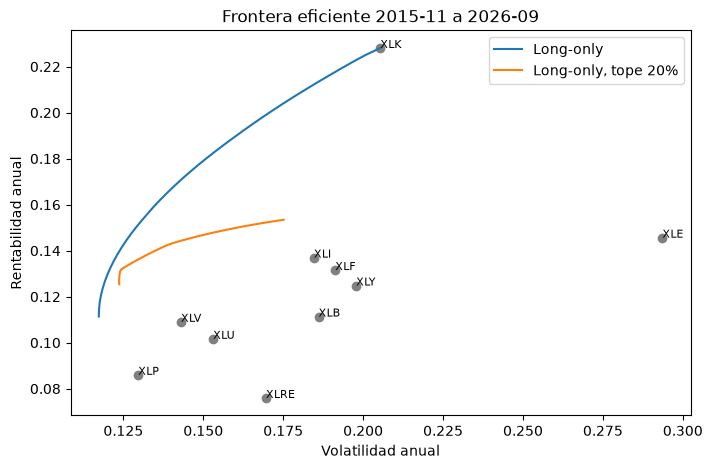

count    40.000000
mean      4.000000
std       1.012739
min       1.000000
25%       3.000000
50%       4.000000
75%       5.000000
max       5.000000
dtype: float64
count    40.000000
mean      6.350000
std       0.533494
min       5.000000
25%       6.000000
50%       6.000000
75%       7.000000
max       7.000000
dtype: float64


In [11]:
import matplotlib.pyplot as plt
from quantmgmt.optimizers.mean_variance import efficient_frontier

fr_libre = efficient_frontier(mu, sigma, n_points=40)
fr_20 = efficient_frontier(mu, sigma, n_points=40, max_weight=0.20)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fr_libre.vol, fr_libre.ret, label="Long-only")
ax.plot(fr_20.vol, fr_20.ret, label="Long-only, tope 20%")
ax.scatter(np.sqrt(np.diag(sigma)), mu, c="grey")
for t in mu.index:
    ax.annotate(t, (np.sqrt(sigma.loc[t, t]), mu[t]), fontsize=8)
ax.set(xlabel="Volatilidad anual", ylabel="Rentabilidad anual", title="Frontera eficiente 2015-11 a 2026-09")
ax.legend(); plt.show()

# concentración: cuántos activos tienen un peso de más del 1% en cada punto
SECT = list(mu.index)
print((fr_libre[SECT] > 0.01).sum(axis=1).describe())
print((fr_20[SECT] > 0.01).sum(axis=1).describe())